# 基于DeepAgents框架的DeepResearch实战

In [1]:
from dotenv import load_dotenv
load_dotenv(".env", override=True)
%load_ext autoreload
%autoreload 2

# 用于研究的深度智能体

我们将使用 `deepagents` 包来创建一个研究智能体。

## 任务特定指令

接下来，让我们使用一些Agent提示技巧定义任务特定指令：

### 1. 像智能体一样思考

你会给新同事什么指令？
- **仔细阅读问题** - 用户需要哪些具体信息？
- **从更广泛的搜索开始** - 首先使用广泛、全面的查询
- **每次搜索后，暂停并评估** - 我掌握的信息是否足够回答？还缺少什么？
- **随着信息的收集，执行更具体的搜索** - 填补信息空白。

### 2. 具体启发式方法（防止过度调用工具导致“失控”）

使用**硬性限制**来防止研究智能体过度调用工具：
- **在能够自信地回答问题时停止** - 不要追求完美。
- **设定预算** - 对于简单的查询，使用 2-3 次搜索工具调用。对于复杂的查询，最多使用 5 次。
- **限制** - 如果在 5 次搜索工具调用后仍找不到合适的资源，请立即停止。

### 3. 展示你的思考过程

每次调用搜索工具后，使用 `think_tool`分析结果：
- 我找到了哪些关键信息？
- 还缺少哪些信息？
- 我掌握的信息是否足以全面回答问题？
- 我应该继续搜索还是直接给出答案？

In [2]:
from research_agent.tools import tavily_search, think_tool
tools = [tavily_search, think_tool]

In [3]:
from datetime import datetime
from utils import show_prompt, format_messages
from research_agent.prompts import (
    RESEARCHER_INSTRUCTIONS,
    RESEARCH_WORKFLOW_INSTRUCTIONS,
    SUBAGENT_DELEGATION_INSTRUCTIONS,
)

In [4]:
show_prompt(RESEARCHER_INSTRUCTIONS)

╭──────────────────────────────────────────────────── Prompt ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│  You are a research assistant conducting research on the user's input topic. For context, today's date is       │
│  {date}.                                                                                                        │
│                                                                                                                 │
│  <Task>                                                                                                         │
│  Your job is to use tools to gather information about the user's input topic.                                   │
│  You can use any of the research tools provided to you to find resources that can help answer the research      │
│  question.                                                                                                      │
│  You can call these tools in series or in parallel, your research is conducted in a tool-calling loop.          │
│  </Task>                                                                                                        │
│                                                                                                                 │
│  <Available Research Tools>                                                                                     │
│  You have access to two specific research tools:                                                                │
│  1. **tavily_search**: For conducting web searches to gather information                                        │
│  2. **think_tool**: For reflection and strategic planning during research                                       │
│  **CRITICAL: Use think_tool after each search to reflect on results and plan next steps**                       │
│  </Available Research Tools>                                                                                    │
│                                                                                                                 │
│  <Instructions>                                                                                                 │
│  Think like a human researcher with limited time. Follow these steps:                                           │
│                                                                                                                 │
│  1. **Read the question carefully** - What specific information does the user need?                             │
│  2. **Start with broader searches** - Use broad, comprehensive queries first                                    │
│  3. **After each search, pause and assess** - Do I have enough to answer? What's still missing?                 │
│  4. **Execute narrower searches as you gather information** - Fill in the gaps                                  │
│  5. **Stop when you can answer confidently** - Don't keep searching for perfection                              │
│  </Instructions>                                                                                                │
│                                                                                                                 │
│  <Hard Limits>                                                                                                  │
│  **Tool Call Budgets** (Prevent excessive searching):                                                           │
│  - **Simple queries**: Use 2-3 search tool calls maximum                                                        │
│  - **Complex queries**: Use up to 5 search tool calls maximum                                                   │
│  - **Always stop**: After 5 search tool calls if you cannot find the right sources                              │
│                                                       

## 特定任务Sub-Agent

可以指定自定义子代理来实现上下文隔离。 这里我们定义了一个可以搜索网络信息的子代理。

In [7]:
# 获取当前的日期
current_date = datetime.now().strftime("%Y-%m-%d")

# 创建研究sub-agent
research_sub_agent = {
    "name": "research-agent",
    "description": "Delegate research to the sub-agent researcher. Only give this researcher one topic at a time.。",
    "system_prompt": RESEARCHER_INSTRUCTIONS.format(date=current_date),
    "tools": [tavily_search, think_tool],
}

## 合并成一个大的PROMPT

In [8]:
# Limits
max_concurrent_research_units = 3
max_researcher_iterations = 3

INSTRUCTIONS = (
    RESEARCH_WORKFLOW_INSTRUCTIONS
    + "\n\n"
    + "=" * 80
    + "\n\n"
    +  SUBAGENT_DELEGATION_INSTRUCTIONS.format(
        max_concurrent_research_units=max_concurrent_research_units,
        max_researcher_iterations=max_researcher_iterations,
    )
)

show_prompt(INSTRUCTIONS)

╭──────────────────────────────────────────────────── Prompt ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│  # Research Workflow                                                                                            │
│                                                                                                                 │
│  Follow this workflow for all research requests:                                                                │
│                                                                                                                 │
│  1. **Plan**: Create a todo list with write_todos to break down the research into focused tasks                 │
│  2. **Save the request**: Use write_file() to save the user's research question to `/research_request.md`       │
│  3. **Research**: Delegate research tasks to sub-agents using the task() tool - ALWAYS use sub-agents for       │
│  research, never conduct research yourself                                                                      │
│  4. **Synthesize**: Review all sub-agent findings and consolidate citations (each unique URL gets one number    │
│  across all findings)                                                                                           │
│  5. **Write Report**: Write a comprehensive final report to `/final_report.md` (see Report Writing Guidelines   │
│  below)                                                                                                         │
│  6. **Verify**: Read `/research_request.md` and confirm you've addressed all aspects with proper citations and  │
│  structure                                                                                                      │
│                                                                                                                 │
│  ## Research Planning Guidelines                                                                                │
│  - Batch similar research tasks into a single TODO to minimize overhead                                         │
│  - For simple fact-finding questions, use 1 sub-agent                                                           │
│  - For comparisons or multi-faceted topics, delegate to multiple parallel sub-agents                            │
│  - Each sub-agent should research one specific aspect and return findings                                       │
│                                                                                                                 │
│  ## Report Writing Guidelines                                                                                   │
│                                                                                                                 │
│  When writing the final report to `/final_report.md`, follow these structure patterns:                          │
│                                                                                                                 │
│  **For comparisons:**                                                                                           │
│  1. Introduction                                                                                                │
│  2. Overview of topic A                                                                                         │
│  3. Overview of topic B                                                                                         │
│  4. Detailed comparison                                                                                         │
│  5. Conclusion                                                                                                  │
│                                                                                                                 │
│  **For lists/rankings:**                              

### 创建Agent

In [9]:
import os
from IPython.display import Image, display
from deepagents import create_deep_agent
from deepagents.backends import FilesystemBackend
from langchain.chat_models import init_chat_model
from langchain_openai import ChatOpenAI

# 加载模型
model = ChatOpenAI(
    api_key=os.getenv("API_KEY"),
    base_url=os.getenv("BASE_URL"),
    model="qwen3-coder-plus",
    temperature=0.7,
)


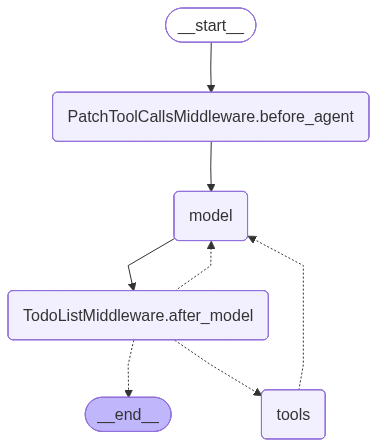

In [10]:
# Create the agent
agent = create_deep_agent(
      model=model,
      tools=tools, 
      system_prompt=INSTRUCTIONS,
      subagents=[research_sub_agent],
      backend=FilesystemBackend(root_dir="/tmp/deepagents/", virtual_mode=True) #
  )
  
# Show the agent
display(Image(agent.get_graph().draw_mermaid_png()))

In [11]:
result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "给我做一个英伟达最新GPU型号的调研报告",
            }
        ],
    }, 
)
format_messages(result["messages"])

╭─────────────────────────────────────────────────── 🧑 Human ────────────────────────────────────────────────────╮
│ 给我做一个英伟达最新GPU型号的调研报告                                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: write_todos                                                                                       │
│    Args: {                                                                                                      │
│   "todos": [                                                                                                    │
│     {                                                                                                           │
│       "content": "\u89c4\u5212\u82f1\u4f1f\u8fbe\u6700\u65b0GPU\u578b\u53f7\u8c03\u7814\u4efb\u52a1",           │
│       "status": "in_progress"                                                                                   │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "\u4fdd\u5b58\u7528\u6237\u7814\u7a76\u8bf7\u6c42\u5230\u6587\u4ef6",                          │
│       "status": "pending"                                                                                       │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content":                                                                                                │
│ "\u59d4\u6258\u5b50\u4ee3\u7406\u8fdb\u884c\u82f1\u4f1f\u8fbe\u6700\u65b0GPU\u578b\u53f7\u7814\u7a76",          │
│       "status": "pending"                                                                                       │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "\u6574\u5408\u7814\u7a76\u7ed3\u679c\u5e76\u64b0\u5199\u6700\u7ec8\u62a5\u544a",              │
│       "status": "pending"                                                                                       │
│     }                                                                                                           │
│   ]                                                                                                             │
│ }                                                                                                               │
│    ID: call_26ab660ea39749d78be3422e                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated todo list to [{'content': '规划英伟达最新GPU型号调研任务', 'status': 'in_progress'}, {'content':        │
│ '保存用户研究请求到文件', 'status': 'pending'}, {'content': '委托子代理进行英伟达最新GPU型号研究', 'status':    │
│ 'pending'}, {'content': '整合研究结果并撰写最终报告', 'status': 'pending'}]                                     │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: write_file                                                                                        │
│    Args: {                                                                                                      │
│   "file_path": "/research_request.md",                                                                          │
│   "content":                                                                                                    │
│ "\u7ed9\u6211\u505a\u4e00\u4e2a\u82f1\u4f1f\u8fbe\u6700\u65b0GPU\u578b\u53f7\u7684\u8c03\u7814\u62a5\u544a"     │
│ }                                                                                                               │
│    ID: call_fce2560bc656439f8e78798e                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated file /research_request.md                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: write_file                                                                                        │
│    Args: {                                                                                                      │
│   "file_path": "/final_report.md",                                                                              │
│   "content": "# \u82f1\u4f1f\u8fbe\u6700\u65b0GPU\u578b\u53f7\u8c03\u7814\u62a5\u544a\n\n##                     │
│ \u6982\u8ff0\n\n\u672c\u62a5\u544a\u8be6\u7ec6\u4ecb\u7ecd\u4e86\u82f1\u4f1f\u8fbe\u6700\u65b0\u7684GPU\u4ea7\u │
│ 54c1\u7ebf\uff0c\u6db5\u76d6\u57fa\u4e8eAda                                                                     │
│ Lovelace\u67b6\u6784\u7684\u6d88\u8d39\u7ea7\u663e\u5361\u548c\u57fa\u4e8eHopper\u67b6\u6784\u7684\u6570\u636e\ │
│ u4e2d\u5fc3GPU\u3002\u8fd9\u4e9b\u4ea7\u54c1\u4ee3\u8868\u4e86\u5f53\u524d\u56fe\u5f62\u5904\u7406\u548cAI\u8ba │
│ 1\u7b97\u9886\u57df\u7684\u6700\u5148\u8fdb\u6280\u672f\u3002\n\n## \u6d88\u8d39\u7ea7GPU\u578b\u53f7 (RTX      │
│ 40\u7cfb\u5217 - Ada Lovelace\u67b6\u6784)\n\n### RTX 4090\n- **\u53d1\u5e03\u65e5\u671f**:                     │
│ 2022\u5e7410\u6708\n- **\u4ef7\u683c**: 1599\u7f8e\u5143\n- **CUDA\u6838\u5fc3\u6570**: 16,384\u4e2a\n-         │
│ **\u663e\u5b58**: 24GB GDDR6X\n- **\u663e\u5b58\u63a5\u53e3**: 384\u4f4d\n- **\u663e\u5b58\u5e26\u5bbd**: 1.0   │
│ TB/s\n- **\u6027\u80fd**: \u76f8\u6bd4RTX 3090\u5e27\u7387\u63d0\u5347\u9ad8\u8fbe89%\n-                        │
│ **\u76ee\u6807\u5e94\u7528**:                                                                                   │
│ 4K/8K\u6e38\u620f\u3001\u4e13\u4e1a\u5185\u5bb9\u521b\u4f5c\u3001AI\u5f00\u53d1\n\n### RTX 4080\n-              │
│ **\u53d1\u5e03\u65e5\u671f**: 2022\u5e7411\u6708\n- **\u4ef7\u683c**: 1199\u7f8e\u5143\n-                       │
│ **CUDA\u6838\u5fc3\u6570**: 9,728\u4e2a\n- **\u663e\u5b58**: 16GB GDDR6X\n- **\u663e\u5b58\u63a5\u53e3**:       │
│ 256\u4f4d\n- **\u663e\u5b58\u5e26\u5bbd**: 717 GB/s\n- **\u6027\u80fd**: \u6bd4RTX 3080 Ti\u5feb39%\n-          │
│ **\u76ee\u6807\u5e94\u7528**: \u9ad8\u7aef4K\u6e38\u620f\u3001\u9ad8\u7ea7\u5185\u5bb9\u521b\u4f5c\n\n### RTX   │
│ 4070 Ti\n- **\u53d1\u5e03\u65e5\u671f**: 2023\u5e741\u6708\n- **\u4ef7\u683c**: 799\u7f8e\u5143\n-              │
│ **CUDA\u6838\u5fc3\u6570**: 7,680\u4e2a\n- **\u663e\u5b58**: 12GB GDDR6X\n- **\u663e\u5b58\u63a5\u53e3**:       │
│ 192\u4f4d\n- **\u663e\u5b58\u5e26\u5bbd**: 504 GB/s\n- **\u6027\u80fd**: \u6bd4RTX                              │
│ 3080\u5feb28%\uff0c\u4ef7\u683c\u9ad814%\n- **\u76ee\u6807\u5e94\u7528**:                                       │
│ \u9ad8\u5206\u8fa8\u7387\u6e38\u620f\u3001\u4e13\u4e1a\u53ef\u89c6\u5316\n\n### RTX 4070\n-                     │
│ **\u53d1\u5e03\u65e5\u671f**: 2023\u5e744\u6708\n- **\u4ef7\u683c**: 599\u7f8e\u5143\n-                         │
│ **CUDA\u6838\u5fc3\u6570**: 5,888\u4e2a\n- **\u663e\u5b58**: 12GB GDDR6X\n- **\u663e\u5b58\u63a5\u53e3**:       │
│ 192\u4f4d\n- **\u663e\u5b58\u5e26\u5bbd**: 504 GB/s\n- **\u76ee\u6807\u5e94\u7528**:                            │
│ 1440p\u6e38\u620f\u3001\u5185\u5bb9\u521b\u4f5c\n\n### RTX 4060 Ti/4060\n- **\u53d1\u5e03\u65e5\u671f**:        │
│ 2023\u5e745\u6708-7\u6708\n- **\u4ef7\u683c\u8303\u56f4**: 299-499\u7f8e\u5143\n- **\u76ee\u6807\u5e94\u7528**: │
│ 1080p/1440p\u6e38\u620f\u3001\u5165\u95e8\u7ea7\u5185\u5bb9\u521b\u4f5c\n\n### RTX 40 Super\u7cfb\u5217         │
│ (\u66f4\u65b0\u578b\u53f7)\n- **RTX 4070 Super**: 599.99\u7f8e\u5143 (2024\u5e741\u670817\u65e5) -              │
│ \u6027\u80fd\u63a5\u8fd1\u539f\u7248RTX 4070 Ti\n- **RTX

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated file /final_report.md                                                                                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: write_todos                                                                                       │
│    Args: {                                                                                                      │
│   "todos": [                                                                                                    │
│     {                                                                                                           │
│       "content": "\u89c4\u5212\u82f1\u4f1f\u8fbe\u6700\u65b0GPU\u578b\u53f7\u8c03\u7814\u4efb\u52a1",           │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "\u4fdd\u5b58\u7528\u6237\u7814\u7a76\u8bf7\u6c42\u5230\u6587\u4ef6",                          │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content":                                                                                                │
│ "\u59d4\u6258\u5b50\u4ee3\u7406\u8fdb\u884c\u82f1\u4f1f\u8fbe\u6700\u65b0GPU\u578b\u53f7\u7814\u7a76",          │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "\u6574\u5408\u7814\u7a76\u7ed3\u679c\u5e76\u64b0\u5199\u6700\u7ec8\u62a5\u544a",              │
│       "status": "completed"                                                                                     │
│     }                                                                                                           │
│   ]                                                                                                             │
│ }                                                                                                               │
│    ID: call_1cef4e3d1e404f44b729289c                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated todo list to [{'content': '规划英伟达最新GPU型号调研任务', 'status': 'completed'}, {'content':          │
│ '保存用户研究请求到文件', 'status': 'completed'}, {'content': '委托子代理进行英伟达最新GPU型号研究', 'status':  │
│ 'completed'}, {'content': '整合研究结果并撰写最终报告', 'status': 'completed'}]                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ 已完成英伟达最新GPU型号的调研报告。报告涵盖了基于Ada Lovelace架构的消费级显卡（RTX                              │
│ 40系列）和基于Hopper架构的数据中心GPU（H100），包括各型号的技术规格、性能特点、目标应用、发布时间和价格信息，以 │
│ 及与前代产品的对比优势。                                                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [12]:
result

{'messages': [HumanMessage(content='给我做一个英伟达最新GPU型号的调研报告', additional_kwargs={}, response_metadata={}, id='752a58f0-9515-4d81-929b-6e920905559b'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'call_26ab660ea39749d78be3422e', 'function': {'arguments': '{"todos": [{"content": "规划英伟达最新GPU型号调研任务", "status": "in_progress"}, {"content": "保存用户研究请求到文件", "status": "pending"}, {"content": "委托子代理进行英伟达最新GPU型号研究", "status": "pending"}, {"content": "整合研究结果并撰写最终报告", "status": "pending"}]}', 'name': 'write_todos'}, 'type': 'function', 'index': 0}], 'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 7170, 'total_tokens': 7271, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}}, 'model_name': 'qwen3-coder-plus', 'system_fingerprint': None, 'id': 'chatcmpl-59705260-7546-975e-9757-d489fe2834e3', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019cd074-9a16-7102-a1e3-6f0b7a868